# One-Class SVM anomaly detection: performance and computing cost

This notebook measures how well the **One-Class SVM** from `SVM.ipynb` detects anomalies on P-1, and estimates what it would cost to run.

The SVM learns a boundary around the (anomaly-free) training data's engineered features. Any test row outside that boundary is flagged as anomalous. Flagged rows are grouped into alert intervals and scored against the expert labels with `evaluate_event_detection()` from `detection.py`.

## Measurements

- Events detected, missed events, false alerts, and event precision, recall, and F1.
- Training (fit) time, reported separately from repeated scoring time.
- Feature-generation, scoring, interval-construction, and complete-pipeline time.
- Peak memory use.
- Estimated monthly computing expense under an explicit AWS Fargate scenario.

## Load P-1 data and labels

In [1]:
from pathlib import Path
import sys
import ast
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

repo_dir = Path.cwd().parent
data_dir = repo_dir / "data" / "data"

if str(repo_dir) not in sys.path:
    sys.path.insert(0, str(repo_dir))

from detection import evaluate_event_detection

channel = "P-1"

train = pd.DataFrame(np.load(data_dir / "train" / f"{channel}.npy"))
test = pd.DataFrame(np.load(data_dir / "test" / f"{channel}.npy"))

labels = pd.read_csv(data_dir / "labeled_anomalies.csv")
labeled_intervals = ast.literal_eval(
    labels.loc[labels["chan_id"] == channel, "anomaly_sequences"].iloc[0])

print("Training shape:", train.shape)
print("Test shape:", test.shape)
print("Known anomaly intervals:", sorted(labeled_intervals))

Training shape: (2872, 25)
Test shape: (8505, 25)
Known anomaly intervals: [[2149, 2349], [3539, 3779], [4536, 4844]]


## Feature engineering

The same rolling-window features as `SVM.ipynb` (window = 50): the current value, rolling mean/min/max/std, the first difference and its rolling std, and rolling sums of the 24 command columns.

Constant and highly correlated (|r| > 0.95) command features are identified **on the training data only** and the same columns are dropped from the test features.

In [2]:
def feature_engineering(df, wind):
    features = pd.DataFrame()
    features["value"] = df[0]
    features["rmean"] = df[0].rolling(window=wind).mean()
    features["diff"] = df[0].diff()
    features["diff_std"] = df[0].diff().rolling(window=wind).std()
    features["rmin"] = df[0].rolling(window=wind).min()
    features["rmax"] = df[0].rolling(window=wind).max()
    features["rstd"] = df[0].rolling(window=wind).std()
    for i in range(1, 25):
        features[f"feature {i}"] = df[i].rolling(window=wind).sum()
    return features.iloc[wind:]


window = 50
train_features = feature_engineering(train, window)

OHF = [f"feature {i}" for i in range(1, 25)]
corr = train_features[OHF].corr().abs()
const_cols = corr.columns[corr.isna().all()].tolist()
upper = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1))
corr_cols = [col for col in upper.columns if (upper[col] > 0.95).any()]
to_drop = const_cols + corr_cols

train_features = train_features.drop(columns=to_drop)
feature_columns = list(train_features.columns)

print("Dropped columns:", to_drop)
print("Training feature rows:", train_features.shape)

Dropped columns: ['feature 4', 'feature 8', 'feature 10', 'feature 12', 'feature 15', 'feature 16', 'feature 20', 'feature 23', 'feature 24', 'feature 6', 'feature 14', 'feature 17', 'feature 18', 'feature 22']
Training feature rows: (2822, 17)


## Select gamma using chronological validation on the training data

As in `SVM.ipynb`, we fix `nu = 0.01` and compare `gamma` in {0.1, 0.01, 0.001} with a 10-split `TimeSeriesSplit` (gap = window) on the training features.

Because the training data contains no anomalies, every flagged validation row is a **false positive**, so candidates are compared by mean validation false-positive rate (FPR). We choose the lowest mean FPR. No test data or labels are used for this choice.

Note: the lowest FPR also tends to favour the most permissive boundary, so this rule can trade away sensitivity.

In [3]:
from sklearn.svm import OneClassSVM
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import TimeSeriesSplit

nu = 0.01
gamma_values = [0.1, 0.01, 0.001]
tscv = TimeSeriesSplit(n_splits=10, gap=window)

def make_model(gamma):
    return Pipeline(steps=[
        ("Scaler", StandardScaler()),
        ("SVM", OneClassSVM(nu=nu, gamma=gamma))])

cv_rows = []
for g in gamma_values:
    for split, (fit_idx, val_idx) in enumerate(tscv.split(train_features)):
        model = make_model(g).fit(train_features.iloc[fit_idx])
        fpr = (model.predict(train_features.iloc[val_idx]) == -1).mean()
        cv_rows.append({"gamma": g, "split": split, "FPR": fpr})

cv_results = pd.DataFrame(cv_rows)
gamma_summary = (cv_results.groupby("gamma")["FPR"]
                 .agg(["mean", "median", "max"])
                 .sort_values("mean"))
display(gamma_summary)

selected_gamma = float(gamma_summary.index[0])
print("Selected gamma:", selected_gamma)

,mean,median,max
gamma,,,
0.001,0.067187,0.019531,0.214844
0.010,0.129297,0.089844,0.351562
0.100,0.372656,0.314453,0.894531


Selected gamma: 0.001


## Fit on all training data and score the test sequence

The selected model is refit on all training feature rows. Test features use the same window and retained columns. Each test feature row keeps its original test index (50 onward), so flagged rows map directly to test time steps.

In [4]:
svm_model = make_model(selected_gamma).fit(train_features)

def build_test_features(test_df):
    return feature_engineering(test_df, window).drop(columns=to_drop)[feature_columns]

def generate_svm_flags(test_df, fitted_model):
    # Return the test indices flagged as outside the learned boundary
    features = build_test_features(test_df)
    flagged = fitted_model.predict(features) == -1
    return features.index.to_numpy()[flagged]

test_features = build_test_features(test)
flagged_indices = generate_svm_flags(test, svm_model)

print("Evaluated test rows:", len(test_features))
print("Flagged rows:", len(flagged_indices),
      f"({len(flagged_indices) / len(test_features):.1%})")

Evaluated test rows: 8455
Flagged rows: 403 (4.8%)


## Turn flagged rows into alert intervals

Because every feature row summarises the previous 50 readings, one unusual reading can flip nearby rows on and off. We therefore merge flags separated by fewer than `window` steps into one alert. This gap is set from the feature window, not tuned on the test labels.

Both the raw consecutive grouping and the merged grouping are reported.

In [5]:
def flags_to_intervals(indices, max_gap=1):
    # Group sorted indices into inclusive (start, end) intervals.
    # Flags whose spacing is <= max_gap join the same interval.
    if len(indices) == 0:
        return []
    indices = np.sort(np.asarray(indices))
    breaks = np.where(np.diff(indices) > max_gap)[0]
    starts = np.r_[indices[0], indices[breaks + 1]]
    ends = np.r_[indices[breaks], indices[-1]]
    return [(int(s), int(e)) for s, e in zip(starts, ends)]

raw_intervals = flags_to_intervals(flagged_indices, max_gap=1)
svm_intervals = flags_to_intervals(flagged_indices, max_gap=window)

raw_evaluation = evaluate_event_detection(raw_intervals, labeled_intervals)
svm_evaluation = evaluate_event_detection(svm_intervals, labeled_intervals)

print("Merged alert intervals:", svm_intervals)

event_order = sorted(range(len(labeled_intervals)), key=lambda i: labeled_intervals[i][0])
for n, i in enumerate(event_order, start=1):
    status = "Detected" if svm_evaluation["detected_event_mask"][i] else "Missed"
    print(f"Event {n} {labeled_intervals[i]}: {status}")

detection_results = pd.DataFrame([
    {"grouping": name, "alert intervals": len(iv), "TP": ev["TP"], "FP": ev["FP"],
     "FN": ev["FN"], "precision": ev["precision"], "recall": ev["recall"], "F1": ev["f1"]}
    for name, iv, ev in [("Raw (gap = 1)", raw_intervals, raw_evaluation),
                         (f"Merged (gap = {window})", svm_intervals, svm_evaluation)]
]).set_index("grouping")
detection_results

Merged alert intervals: [(751, 765), (907, 907), (1248, 1271), (1378, 1380), (1824, 1833), (2183, 2183), (2239, 2260), (2507, 2531), (2670, 2702), (2840, 2847), (3000, 3000), (3602, 3622), (3677, 3704), (4100, 4100), (4242, 4242), (4372, 4372), (4532, 4599), (4660, 4683), (4778, 4832), (4938, 4940), (5419, 5419), (5515, 5560), (6035, 6045), (6344, 6346), (6533, 6545), (6849, 6888), (7032, 7080), (8332, 8332), (8402, 8402)]
Event 1 [2149, 2349]: Detected
Event 2 [3539, 3779]: Detected
Event 3 [4536, 4844]: Detected


,alert intervals,TP,FP,FN,precision,recall,F1
grouping,,,,,,,
Raw (gap = 1),47,3,39,0,0.071429,1.0,0.133333
Merged (gap = 50),29,3,22,0,0.120000,1.0,0.214286


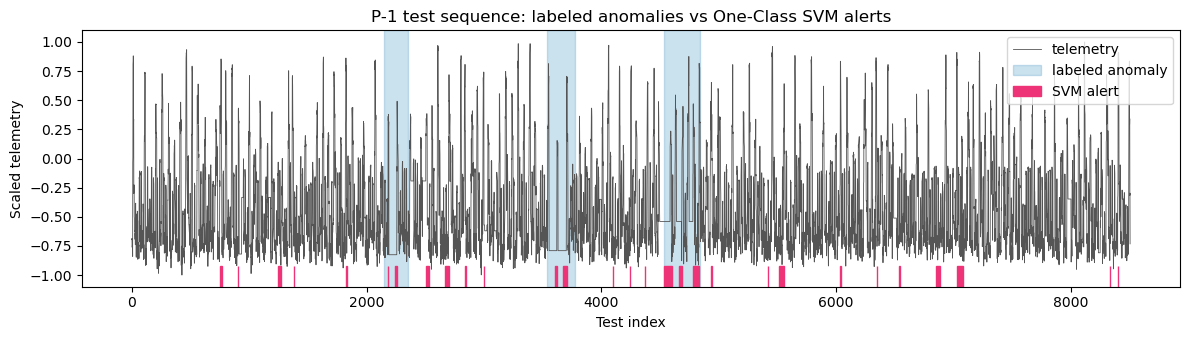

In [6]:
fig, ax = plt.subplots(figsize=(12, 3.5))
ax.plot(test.index, test[0], lw=0.6, color="#555555", label="telemetry")
for k, (s, e) in enumerate(labeled_intervals):
    ax.axvspan(s, e, color="#67a9cf", alpha=0.35, label="labeled anomaly" if k == 0 else None)
for k, (s, e) in enumerate(svm_intervals):
    ax.axvspan(s, e, ymin=0, ymax=0.08, color="#EE3377", label="SVM alert" if k == 0 else None)
ax.set_title("P-1 test sequence: labeled anomalies vs One-Class SVM alerts")
ax.set_xlabel("Test index")
ax.set_ylabel("Scaled telemetry")
ax.legend(loc="upper right")
plt.tight_layout()
plt.show()

## Computational benchmark

Measurement procedure:

1. One warm-up run before measuring.
2. Seven repetitions; `timeit.autorange()` picks enough calls per repeat for at least ~0.2 s.
3. Report the median and interquartile range in milliseconds per batch (the full P-1 test sequence).
4. Limit numerical libraries to one thread.

Stages:

- **Feature generation:** rolling-window features for the test sequence.
- **Scoring:** scaler + One-Class SVM `predict` on precomputed features.
- **Interval construction:** grouping flagged rows into alerts.
- **Complete pipeline:** raw test data to alert intervals in one call.

Model fitting is a one-off training cost and is timed separately. Data loading, plotting, and label evaluation are excluded.

In [7]:
import timeit
from threadpoolctl import threadpool_limits

def run_complete_svm_pipeline():
    return flags_to_intervals(generate_svm_flags(test, svm_model), max_gap=window)

assert run_complete_svm_pipeline() == svm_intervals

operations = {
    "Feature generation": lambda: build_test_features(test),
    "Scoring": lambda: svm_model.predict(test_features),
    "Interval construction": lambda: flags_to_intervals(flagged_indices, max_gap=window),
    "Complete pipeline": run_complete_svm_pipeline,
}

runtime_rows = []
with threadpool_limits(limits=1):
    for stage, operation in operations.items():
        operation()  # warm-up
        timer = timeit.Timer(operation)
        calls_per_repeat, _ = timer.autorange()
        ms = np.asarray(timer.repeat(repeat=7, number=calls_per_repeat)) / calls_per_repeat * 1000
        runtime_rows.append({
            "stage": stage,
            "calls per repeat": calls_per_repeat,
            "median_ms": np.median(ms),
            "q25_ms": np.percentile(ms, 25),
            "q75_ms": np.percentile(ms, 75)})

    # Training cost, timed separately
    fit_ms = np.asarray(timeit.Timer(lambda: make_model(selected_gamma).fit(train_features))
                        .repeat(repeat=5, number=1)) * 1000

svm_runtime = pd.DataFrame(runtime_rows).set_index("stage")
display(svm_runtime)
print(f"Training (fit) median: {np.median(fit_ms):.1f} ms "
      f"(IQR {np.percentile(fit_ms, 25):.1f}-{np.percentile(fit_ms, 75):.1f} ms)")

,calls per repeat,median_ms,q25_ms,q75_ms
stage,,,,
Feature generation,20,16.532845,16.367270,16.735485
Scoring,10,25.151350,24.925280,25.554185
Interval construction,10000,0.035815,0.034927,0.039603
Complete pipeline,5,46.601300,46.133790,47.849600


Training (fit) median: 13.7 ms (IQR 13.2-13.8 ms)


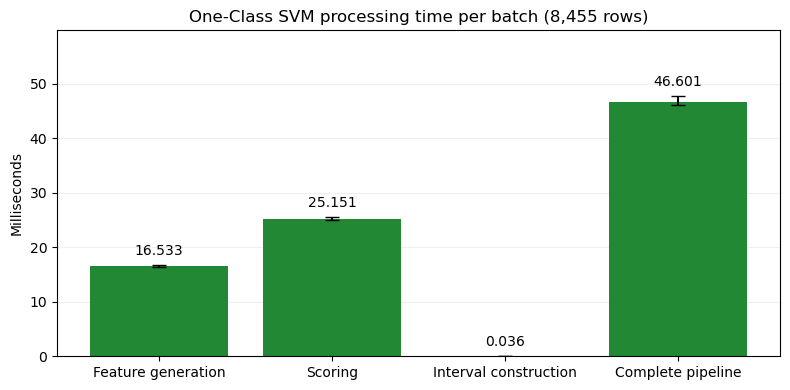

In [8]:
med = svm_runtime["median_ms"].to_numpy()
err = np.vstack([med - svm_runtime["q25_ms"], svm_runtime["q75_ms"] - med])

fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.bar(svm_runtime.index, med, yerr=err, capsize=5, color="#228833")
ax.bar_label(bars, labels=[f"{v:.3f}" for v in med], padding=5)
ax.set_title(f"One-Class SVM processing time per batch ({len(test_features):,} rows)")
ax.set_ylabel("Milliseconds")
ax.set_ylim(0, svm_runtime["q75_ms"].max() * 1.25)
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)
plt.tight_layout()
plt.show()

### Peak memory

Measured with `tracemalloc` in a separate run, so monitoring overhead does not affect the timings above. `tracemalloc` tracks Python-level allocations (including NumPy arrays), not total process memory.

In [9]:
import tracemalloc

def peak_memory_mb(operation):
    tracemalloc.start()
    operation()
    _, peak = tracemalloc.get_traced_memory()
    tracemalloc.stop()
    return peak / 1024**2

pd.Series({
    "Training (fit)": peak_memory_mb(lambda: make_model(selected_gamma).fit(train_features)),
    "Complete pipeline": peak_memory_mb(run_complete_svm_pipeline),
}, name="peak MB").to_frame()

,peak MB
Training (fit),0.836938
Complete pipeline,3.524436


## Illustrative ground-computing cost scenario

**Price reference:** [AWS Fargate pricing](https://aws.amazon.com/fargate/pricing/), Example 1, Linux/x86, US East (N. Virginia): **\$0.000011244** per vCPU-second and **\$0.000001235** per GB-second, per-second billing with a one-minute minimum, rounded up to whole seconds. The pipeline has not been deployed on AWS.

**Assumptions:**

- Allocate **1 vCPU and 2 GB of memory**.
- Process **1,000 P-1-sized batches per day** for **30 days**.
- One task per day, batches processed sequentially, then the task terminates.
- **30 seconds per daily task** of startup and other overhead.
- Cloud processing times of **0.5×, 1×, and 2×** the local benchmark.
- Exclude parameter selection, storage, networking, logging, taxes, and human alert investigation. Training is reported separately as a one-off cost.

With $t_{\mathrm{batch}}$ the measured complete-pipeline time in seconds and $s$ the cloud-to-local multiplier:

$$
t_{\mathrm{daily}} = 1000 \times t_{\mathrm{batch}} \times s + 30
$$

$$
C_{\mathrm{month}} = 30 \times \max(60,\lceil t_{\mathrm{daily}}\rceil) \times \left(r_{\mathrm{CPU}} + 2r_{\mathrm{memory}}\right)
$$

Here $r_{\mathrm{CPU}}$ is the price per vCPU-second and $r_{\mathrm{memory}}$ the price per GB-second.

In [10]:
cpu_price_per_second = 0.000011244
memory_price_per_gb_second = 0.000001235

allocated_vcpus = 1
allocated_memory_gb = 2

batches_per_day = 1000
days_per_month = 30
startup_seconds_per_day = 30
runtime_multipliers = [0.5, 1.0, 2.0]

allocated_price_per_second = (
    allocated_vcpus * cpu_price_per_second
    + allocated_memory_gb * memory_price_per_gb_second)

batch_seconds = svm_runtime.loc["Complete pipeline", "median_ms"] / 1000

cost_rows = []
for multiplier in runtime_multipliers:
    processing_seconds = batches_per_day * batch_seconds * multiplier
    daily_task_seconds = processing_seconds + startup_seconds_per_day
    billed_seconds_per_day = max(60, int(np.ceil(daily_task_seconds)))
    monthly_cost = billed_seconds_per_day * days_per_month * allocated_price_per_second
    cost_rows.append({
        "runtime multiplier": multiplier,
        "processing seconds per day": processing_seconds,
        "billed seconds per day": billed_seconds_per_day,
        "estimated monthly USD": monthly_cost})

cost_estimates = pd.DataFrame(cost_rows)
display(cost_estimates.round(4))

# One-off training task under the same billing rules (single fit + overhead)
fit_seconds = np.median(fit_ms) / 1000
training_cost = max(60, int(np.ceil(fit_seconds + startup_seconds_per_day))) * allocated_price_per_second
print(f"One-off training task (fit + 30 s overhead, 60 s minimum): ${training_cost:.5f}")

always_running_monthly_cost = days_per_month * 24 * 3600 * allocated_price_per_second
print(f"Same allocation running continuously for 30 days: ${always_running_monthly_cost:.2f}")

,runtime multiplier,processing seconds per day,billed seconds per day,estimated monthly USD
0,0.5,23.3006,60,0.0247
1,1.0,46.6013,77,0.0317
2,2.0,93.2026,124,0.0510


One-off training task (fit + 30 s overhead, 60 s minimum): $0.00082
Same allocation running continuously for 30 days: $35.55


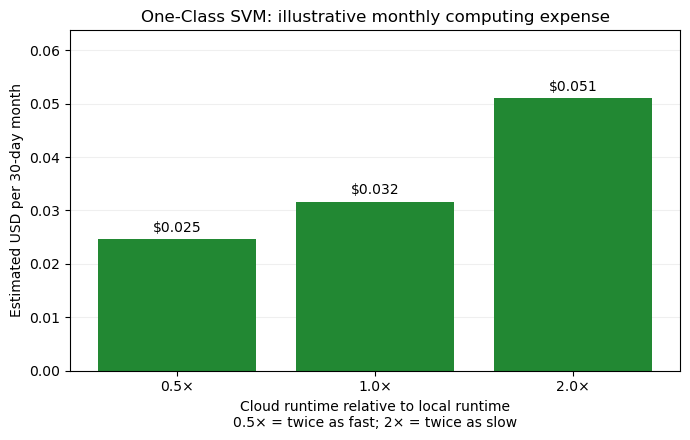

In [11]:
fig, ax = plt.subplots(figsize=(7, 4.5))
bars = ax.bar([f"{m}×" for m in cost_estimates["runtime multiplier"]],
              cost_estimates["estimated monthly USD"], color="#228833")
ax.bar_label(bars, fmt="$%.3f", padding=3)
ax.set_title("One-Class SVM: illustrative monthly computing expense")
ax.set_xlabel("Cloud runtime relative to local runtime\n0.5× = twice as fast; 2× = twice as slow")
ax.set_ylabel("Estimated USD per 30-day month")
ax.set_ylim(0, cost_estimates["estimated monthly USD"].max() * 1.25)
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)
plt.tight_layout()
plt.show()

## Results

**Detection.** With gamma = 0.001 (the lowest validation FPR), the One-Class SVM flagged about 4.8% of the 8,455 scored test rows. After merging nearby flags it produced **29 alert intervals**. These overlap **all three known events (recall = 1.0)**, but **22 are false alerts (precision = 0.12, F1 ≈ 0.21)**.

**Runtime.** The complete pipeline took about **47 ms per batch**: roughly 17 ms for feature generation and 25 ms for scoring, with interval construction negligible. Training takes about 14 ms per fit. Peak traced memory was about 3.5 MB.

**Cost.** Under the stated scenario, the estimated monthly expense is about **2.5, 3.2, and 5.1 cents** at 0.5×, 1×, and 2× runtime. At 0.5×, the 60-second minimum billing sets the cost. A one-off training task costs less than a tenth of a cent. Keeping the same resources running continuously would cost **$35.55/month**, so the operating schedule matters far more than the processing time.

**Takeaway.** Running the SVM is very cheap, but at this operating point it produces many false alerts. Its real cost would most likely be the human time spent reviewing those alerts.

*Exact timings vary between runs; the figures above come from the executed run saved in this notebook.*

## Caveats

- These are batch-processing measurements on the computer running this notebook, not real-time latency or measured cloud results.
- Alert intervals depend on the merge gap (= feature window). It was fixed before looking at labels but is still a design choice.
- Gamma was chosen by validation FPR on normal-only training data, which does not directly measure the ability to catch anomalies.
- Cost excludes human time spent investigating alerts, which grows with the number of false alerts.
- P-1 is a single-channel case study.